# Geometric Intuitions of PCA

Principal Component Analysis (PCA) is a dimensionality reduction technique. It
is an unsupervised learning method, i.e. it works with features only but there
is **no target variable**.

The objective of this notebook is to build up our geometric intuition using a
simple 2D feature space. For this purpose we load the penguins dataset and
keep two features that are correlated: the length and depth of the culmen. As
this is an unsupervised task, the idea is not to predict either feature, for
example by fitting a regression line, but rather to measure how much
independent information can be obtained from each of them.

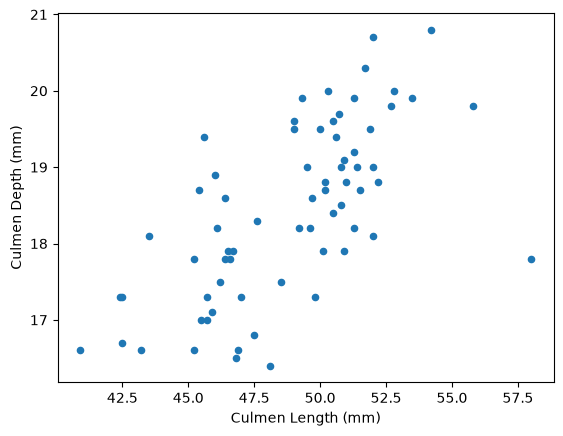

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

penguins = pd.read_csv("../datasets/penguins_classification.csv")
penguins = penguins[penguins["Species"] == "Chinstrap"]
penguins = penguins.drop(columns="Species")
_ = penguins.plot.scatter(x="Culmen Length (mm)", y="Culmen Depth (mm)")

## Finding the principal component

PCA is intended to find new features (called principal components, or "PC")
that capture enough of the structure in our data.

The first PC is the direction along which our data varies the most. Because
our features are correlated, there is a clear dominant pattern in the data
which PCA can identify. The second PC would align with the direction with
second to most variance, and so on.

We begin by extracting both components (`n_components` = `n_features`) to
understand the full picture. **This is not dimensional reduction yet**. In
this case the components are linear combinations of the (centered) original
features, in other words, just a change of basis to a more convenient
coordinate system.

In [2]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca.fit(penguins)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",2
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

### Understanding PCA attributes

After fitting, `PCA` provides a `components_` attribute, which is an array of
shape `(n_components, n_features)`. Each row is a PC, each column corresponds
to original features:

In [3]:
pca.components_

array([[ 0.97301717,  0.23073271],
       [-0.23073271,  0.97301717]])

These `components_` tell us how to create the new features (after centering):

In [4]:
feature_names = penguins.columns.tolist()
for i, component in enumerate(pca.components_):
    terms = " + ".join(
        f"{w:.1f} * ({f} - {m:.1f})"
        for w, f, m in zip(component, feature_names, pca.mean_)
    )
    print(f"PC{i + 1} = {terms}")

PC1 = 1.0 * (Culmen Length (mm) - 48.8) + 0.2 * (Culmen Depth (mm) - 18.4)
PC2 = -0.2 * (Culmen Length (mm) - 48.8) + 1.0 * (Culmen Depth (mm) - 18.4)


The components are perpendicular to each other. Indeed, components in the
space of reduced dimensions work as new coordinate axes. We can plot them to
better visualize the effect.

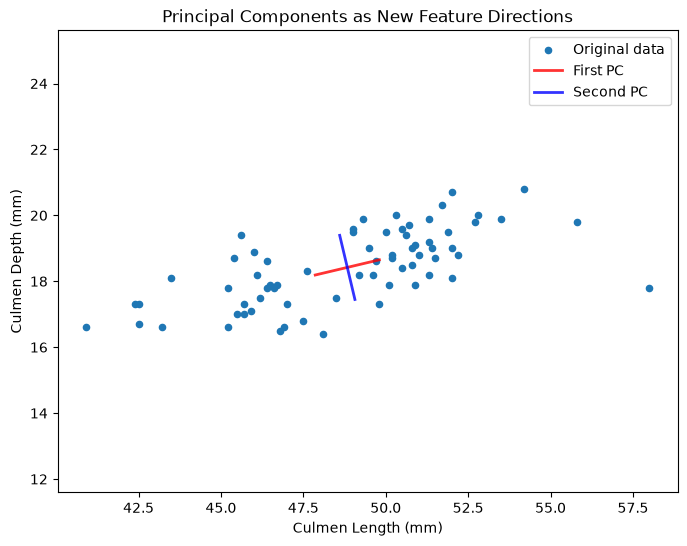

In [5]:
import numpy as np

fig, ax = plt.subplots(figsize=(8, 6))

penguins.plot.scatter(
    x="Culmen Length (mm)", y="Culmen Depth (mm)", label="Original data", ax=ax
)
center = penguins[["Culmen Length (mm)", "Culmen Depth (mm)"]].mean().values
for component, color, label in zip(
    pca.components_,
    ["red", "blue"],
    ["First PC", "Second PC"],
):
    # Draw axes defining the PC space
    endpoints = np.array([center - component, center + component])
    ax.plot(
        endpoints[:, 0],
        endpoints[:, 1],
        color=color,
        linewidth=2,
        label=label,
        alpha=0.8,
    )
ax.legend()
ax.axis("equal")
_ = ax.set_title("Principal Components as New Feature Directions")

The red line shows the first PC. It follows the correlation pattern in our
data. The blue line (second PC) is perpendicular and captures the remaining
variance.

Another important attribute of `PCA` is the `explained_variance_`. By plotting
it we can confirm quantitatively what we know: the first PC "explains" most of
the variance. In other words, our data is more spread over the direction of
the first PC.

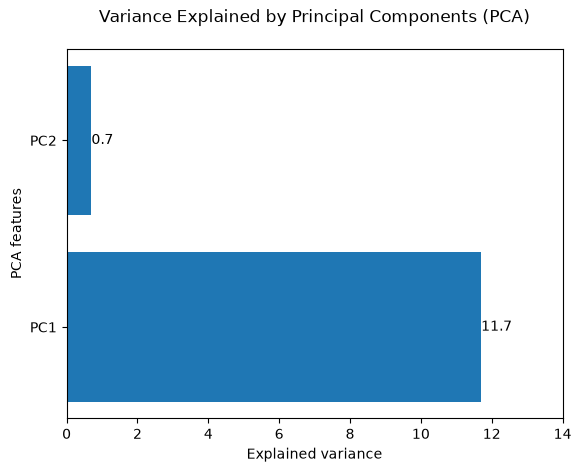

In [6]:
fig, ax = plt.subplots()
bars = ax.barh(
    range(1, len(pca.explained_variance_) + 1),
    pca.explained_variance_.round(decimals=1),
)
ax.bar_label(bars)
ax.set_xlim([0, 14])
ax.set_yticks([1, 2], labels=["PC1", "PC2"])
ax.set_xlabel("Explained variance")
ax.set_ylabel("PCA features")
_ = ax.set_title("Variance Explained by Principal Components (PCA)", y=1.05)

The `explained_variance_`, is the statistical variance (as computed by the
method `var`) of the PC space, in other words, in the new space obtained by
transforming the original `penguins.values` using the matrix defined by
`pca.components_`.

In [7]:
print(pca.explained_variance_)
print(
    (penguins.values @ pca.components_.T).var(axis=0, ddof=1)
)  # ddof scales by n_samples-1

[11.73819374  0.70155823]
[11.73819374  0.70155823]


Remember that the variance is simply the square of the standard deviation:

In [8]:
pca_std = np.sqrt(pca.explained_variance_)
print(f"Std along the first PC : {pca_std[0]:.3f} mm")
print(f"Std along the second PC : {pca_std[1]:.3f} mm")

Std along the first PC : 3.426 mm
Std along the second PC : 0.838 mm


As both features share the same unit (mm), the standard deviation of each
component is still interpretable in mm in this particular case. But in the
general case PCA can mix heterogeneous units from different features, making
such interpretation meaningless.

If we are more interested in the proportion of the total variance carried by
each component, and not so much on the original scale, we can make use of the
`explained_variance_ratio_` attribute:

In [9]:
# total_explained_variance = pca.explained_variance_.sum()
for i, var_ratio in enumerate(pca.explained_variance_ratio_):
    print(f"PC{i + 1} carries {100 * var_ratio:.1f}% of the total variance")

PC1 carries 94.4% of the total variance
PC2 carries 5.6% of the total variance


Percentages can also be obtained directly from the `explained_variance_`:

In [10]:
100 * pca.explained_variance_ / pca.explained_variance_.sum()

array([94.36035193,  5.63964807])

Notice that how much data spreads over a given direction strongly depends on
the scale of the original features, but we will discuss the need for scaling
in the next notebook.

## Dimensionality reduction from 2D to 1D

As we saw, PCA is a transformation to a PC space where axes align with the
directions of maximum variance. What makes this interesting is when used as a
dimensionality reduction technique. In this case we can represent our 2D data
using just the first principal component, effectively reducing from 2 features
to 1.

This works well here because our original features were correlated. One degree
of freedom suffices to capture most of the information, which is the overall
size of the penguin.

In [11]:
# Transform to principal component space
pca_1d = PCA(n_components=1)
penguins_transformed = pca_1d.fit_transform(penguins)

print(f"Original shape: {penguins.shape} (samples, features)")
print(f"Transformed shape: {penguins_transformed.shape} (samples, components)")

Original shape: (68, 2) (samples, features)
Transformed shape: (68, 1) (samples, components)


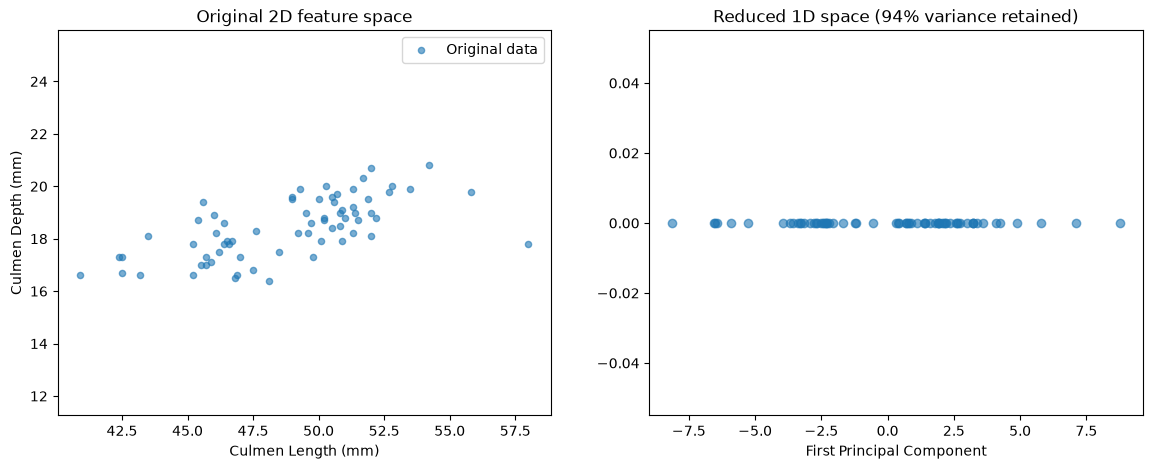

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

penguins.plot.scatter(
    x="Culmen Length (mm)",
    y="Culmen Depth (mm)",
    label="Original data",
    alpha=0.6,
    ax=ax1,
)
ax1.set_title("Original 2D feature space")
ax1.axis("equal")

ax2.scatter(
    penguins_transformed.ravel(),
    np.zeros(len(penguins_transformed)),
    alpha=0.6,
)
ax2.set_xlabel("First Principal Component")
_ = ax2.set_title(
    f"Reduced 1D space ({pca_1d.explained_variance_ratio_[0]:.0%} variance retained)"
)

The transformation creates a new 1D representation where samples that were
close in the original 2D space remain close in the new 1D space. The structure
is preserved.

## Loss of information during reconstruction

When we use fewer components than original features, we lose some information.
The `inverse_transform` method shows us what our data looks like when reconstructed
from the reduced representation.

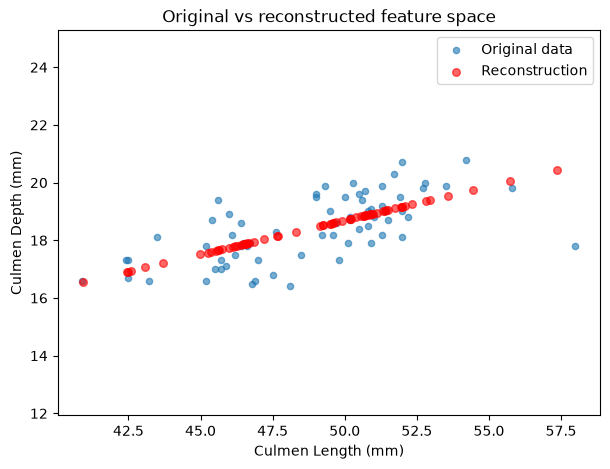

In [13]:
penguins_reconstructed = pca_1d.inverse_transform(penguins_transformed)

fig, ax = plt.subplots(figsize=(7, 5))
penguins.plot.scatter(
    x="Culmen Length (mm)",
    y="Culmen Depth (mm)",
    label="Original data",
    alpha=0.6,
    ax=ax,
)
ax.scatter(
    penguins_reconstructed[:, 0],
    penguins_reconstructed[:, 1],
    alpha=0.6,
    s=30,
    color="red",
    label="Reconstruction",
)
ax.axis("equal")
ax.legend()
_ = ax.set_title("Original vs reconstructed feature space")

The reconstructed points all lie on a line, that is, we have lost the variance
perpendicular to it, but retained the main pattern. The `inverse_transform` is
a rotation back to the original axes, that in this case maps the 1D
representation back into 2D. The variance along the remaining component was
already discarded during the forward projection, which is why the points
collapse onto a line.

One geometrically intuitive way to quantify the information lost during
dimensionality reduction is the squared Euclidean distance between the
original feature vector and its reconstruction, then averaged over all
samples. This is different from a flat mean over all elements, as we first sum
the squared differences across features (`axis=1`), preserving the geometric
notion of distance in more than 1 dimension, and only then averaging over
samples.

In [14]:
reconstruction_error = np.mean(
    np.sum((penguins - penguins_reconstructed) ** 2, axis=1)
)
print(f"Mean squared reconstruction error: {reconstruction_error:.4f}")

Mean squared reconstruction error: 0.6912


## PCA vs Linear Regression

From this example it might be tempting to compare PCA with linear regression
since both can produce lines through data. To illustrate the difference, let's
pretend for a moment that "Culmen Depth (mm)" is a target for regression.

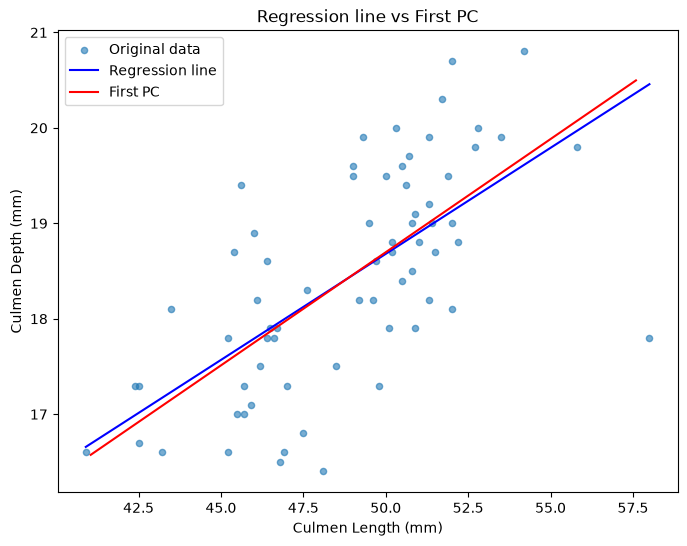

In [15]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(penguins[["Culmen Length (mm)"]], penguins["Culmen Depth (mm)"])

x1_range = pd.DataFrame(
    {
        "Culmen Length (mm)": np.linspace(
            penguins["Culmen Length (mm)"].min(),
            penguins["Culmen Length (mm)"].max(),
            100,
        )
    }
)
x2_pred = lr.predict(x1_range)
center = pca_1d.mean_
direction = pca_1d.components_[0]
t = np.linspace(-8, 9, 100)
pc_line = center + t[:, np.newaxis] * direction

fig, ax = plt.subplots(figsize=(8, 6))
penguins.plot.scatter(
    x="Culmen Length (mm)",
    y="Culmen Depth (mm)",
    label="Original data",
    alpha=0.6,
    ax=ax,
)
ax.plot(x1_range, x2_pred, "b-", label="Regression line")
ax.plot(pc_line[:, 0], pc_line[:, 1], "r-", label="First PC")
ax.legend()
_ = ax.set_title("Regression line vs First PC")

The slopes are slightly different. Indeed :
- Linear regression minimises the vertical distance (residuals in the
  y-direction only) between each point and the line. It treats the two
  features asymmetrically, with one as predictor and one as target.
- PCA minimises the perpendicular distance from each point to the line. It
  treats both features symmetrically, with no notion of predictor/target.

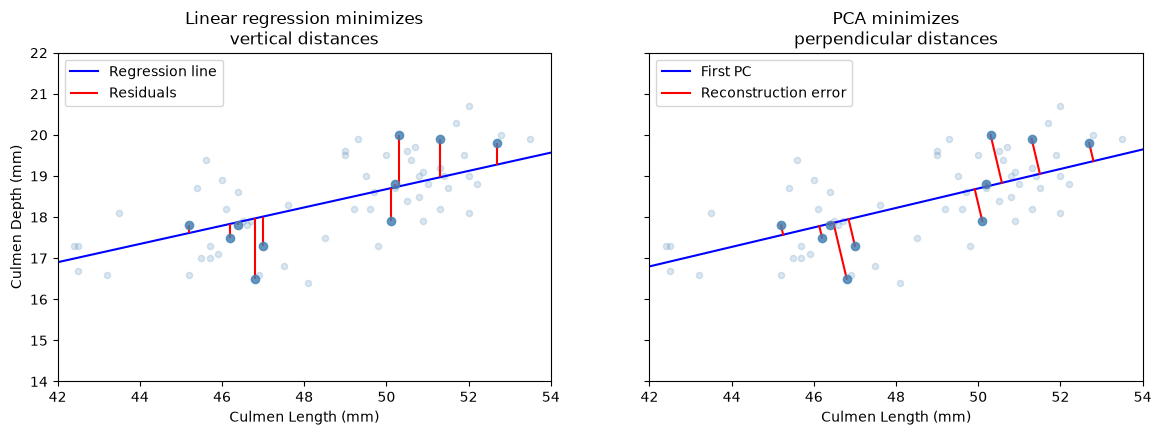

In [16]:
X_plot = penguins.sample(10, random_state=42)
X_plot_pred = lr.predict(X_plot[["Culmen Length (mm)"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax in axes:
    penguins.plot.scatter(
        x="Culmen Length (mm)",
        y="Culmen Depth (mm)",
        alpha=0.2,
        color="steelblue",
        ax=ax,
    )
    ax.scatter(
        X_plot["Culmen Length (mm)"],
        X_plot["Culmen Depth (mm)"],
        color="steelblue",
        alpha=0.8,
        zorder=3,
    )

axes[0].plot(x1_range, x2_pred, "b-", label="Regression line")
axes[0].vlines(
    X_plot["Culmen Length (mm)"],
    X_plot["Culmen Depth (mm)"],
    X_plot_pred,
    color="red",
    label="Residuals",
)
axes[0].set_title("Linear regression minimizes\nvertical distances")

axes[1].plot(pc_line[:, 0], pc_line[:, 1], "b-", label="First PC")
points = X_plot.values
t_proj = (points - center) @ direction
projections = center + t_proj[:, np.newaxis] * direction

for point, proj in zip(points, projections):
    axes[1].plot([point[0], proj[0]], [point[1], proj[1]], color="red")
axes[1].plot([], [], color="red", label="Reconstruction error")
axes[1].set_title("PCA minimizes\nperpendicular distances")

for ax in axes:
    ax.set(xlim=(42, 54), ylim=(14, 22), aspect="equal")
    ax.legend(loc="upper left")

plt.show()

## Key Takeaways

- PCA is **an unsupervised learning method**. It works with features only,
  treating them symmetrically.
- PCA creates a new feature space defined by the principal components as
  weighted combinations of the original features.
- If the principal components space has lower dimension that the original
  feature space, PCA does dimensionality reduction.
- By keeping components with high variance, we preserve the main patterns in
  the data.
- Using fewer components than original dimensions means accepting some
  information loss for the benefit of simplicity.

Next, we'll explore how PCA behaves with outliers and noise, helping you
understand when PCA works well and when to be cautious.